# DistilBERT for Multi-Label Toxicity Classification
**Transformer Model Development.** Toxic Comment Detection and Explainable Content Moderation.

This notebook picks up exactly where Member 1 stopped. It reads Member 1's `processed_data` folder (`train/val/test.parquet`, `dataset_card.json`), fine-tunes DistilBERT, tunes a decision threshold per label, evaluates on the untouched test split, compares against the TF-IDF baseline and saves everything Members 3, 4 and 5 need.

**What you get at the end**

| Output | Used by |
|---|---|
| `model/` (weights + config) and `tokenizer/` | Members 4 and 5 |
| `thresholds.json` (one threshold per label) | Members 4 and 5 |
| `test_predictions.parquet` and `val_predictions.parquet` (probabilities + identity columns) | Member 3 (fairness), Member 4 (calibration, abstention) |
| `metrics_test.csv`, `baseline_vs_distilbert.csv`, figures | Report |

**Before you run anything**
1. `Runtime > Change runtime type > T4 GPU`.
2. Upload `processed_data.zip` to Google Drive and (optionally) `toxic_preprocessing.py` to the Colab file panel.
3. Edit the paths in section 1, then run top to bottom.

**Key design decisions** (so you can explain them in the viva)

| Decision | Choice | Why |
|---|---|---|
| Text column | `text_raw` | Member 1 kept casing and punctuation for transformers. SHOUTING is a real toxicity signal (see `03_length_caps.png`). |
| Model | `distilbert-base-cased` | Cased vocabulary keeps the capitalisation signal. Switch to `-uncased` in the config if you want to test it. |
| Output layer | 6 independent sigmoids | Labels overlap (`insult` with `toxic` is 0.72), so this is multi-label, not softmax. |
| `severe_toxic` | Dropped | Only 13 positives. Member 1 already excluded it (`labels_model`). |
| Loss | `BCEWithLogitsLoss` with softened `pos_weight` | Raw weights go up to 424 and make training unstable. We use `pos_weight ** 0.5` and fix the rest with per-label thresholds. |
| Batching | Dynamic padding, length-bucketed | Median comment is about 30 words. Padding everything to 240 tokens would waste most of the GPU time. |
| Thresholds | Tuned per label on **val**, reported on **test** | Tuning on test would inflate the numbers. |

## 1. Setup and configuration

In [2]:
%pip install -q transformers pyarrow scikit-learn

In [3]:
import os, re, json, time, glob, math, shutil, zipfile, warnings, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, multilabel_confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 50)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"            # fp16 mixed precision: about 2x faster and half the memory on a T4
print("Device:", device, "|", torch.cuda.get_device_name(0) if use_amp else "NO GPU, switch the runtime to T4 GPU")
print("torch", torch.__version__)

Device: cuda | Tesla T4
torch 2.11.0+cu130


In [4]:
# ============================ EDIT THIS CELL ============================
# ---- where things live ----
DRIVE_ZIP_PATH = "/content/drive/MyDrive/processed_data.zip"     # your uploaded zip
GDRIVE_FILE_ID = "1ZNK9NN_yKcVta_mwMZZj9b4kdkIYfrFC"           # fallback: download with gdown if the zip path above is not found
OUT_DIR = Path("/content/drive/MyDrive/toxic_project/member2_outputs")  # outputs + checkpoints (on Drive so a disconnect does not lose them)
LOCAL_DATA = Path("/content/processed_data")                    # where the zip is extracted (fast local disk)

# ---- model ----
MODEL_NAME  = "distilbert-base-cased"   # or "distilbert-base-uncased"
MAX_LEN     = None                      # None = use suggested_max_length (240) from dataset_card.json

# ---- training budget ----
# Full train split = 1.41M comments. A T4 does roughly 400-600 comments/s with dynamic padding, so a full epoch
# takes about 45-60 min. Start with a sample; go to None (all rows) only when everything works end to end.
TRAIN_SAMPLE = 500_000      # None = full train split
EPOCHS       = 2
BATCH_SIZE   = 64
LR           = 3e-5
WARMUP_FRAC  = 0.06
WEIGHT_DECAY = 0.01
GRAD_CLIP    = 1.0
POS_WEIGHT_POWER = 0.5      # 1.0 = full pos_weight from dataset_card, 0.5 = sqrt (recommended), 0 = unweighted

# ---- housekeeping ----
SEED = 42
VAL_SUBSET_FOR_EPOCH_EVAL = 30_000   # quick validation after each epoch (the full val set is used for thresholds)
CKPT_EVERY_STEPS = 1000              # resume point; Colab can disconnect at any time
RESUME = True
DEBUG_SMOKE_TEST = False             # True = 20k train / 5k val / 5k test, 1 epoch. Use it once to check the pipeline in 3 minutes.
# ========================================================================

np.random.seed(SEED); torch.manual_seed(SEED)

## 2. Get the data from Google Drive
This mounts Drive, copies the zip to the local Colab disk (reading 600 MB from Drive on every run is slow) and unzips it. If the zip is not at `DRIVE_ZIP_PATH`, it searches your Drive for `processed_data*.zip`, then falls back to `gdown` using the file id (works only if the link is shared as "Anyone with the link").

In [5]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    print("Not running in Colab: set DRIVE_ZIP_PATH / OUT_DIR to local paths.")

OUT_DIR.mkdir(parents=True, exist_ok=True)

def find_data_dir(root):
    hits = glob.glob(str(Path(root) / "**" / "train.parquet"), recursive=True)
    return Path(hits[0]).parent if hits else None

DATA_DIR = find_data_dir(LOCAL_DATA) if LOCAL_DATA.exists() else None
if DATA_DIR is None:
    zip_src = Path(DRIVE_ZIP_PATH)
    if not zip_src.exists():
        cand = glob.glob("/content/drive/MyDrive/**/processed_data*.zip", recursive=True)
        if cand: zip_src = Path(cand[0]); print("Found zip at", zip_src)
    local_zip = Path("/content/processed_data.zip")
    if zip_src.exists():
        print("Copying zip to local disk ..."); shutil.copy(zip_src, local_zip)
    else:
        print("Zip not found on Drive, trying gdown ...")
        import gdown
        gdown.download(id=GDRIVE_FILE_ID, output=str(local_zip), quiet=False)
    print("Unzipping ...")
    with zipfile.ZipFile(local_zip) as z: z.extractall(LOCAL_DATA)
    DATA_DIR = find_data_dir(LOCAL_DATA)
    local_zip.unlink(missing_ok=True)

assert DATA_DIR is not None, "train.parquet not found after unzipping"
print("DATA_DIR =", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

Mounted at /content/drive
Copying zip to local disk ...
Unzipping ...
DATA_DIR = /content/processed_data/processed_data
['cleaning_impact.csv', 'cleaning_log.csv', 'dataset_card.json', 'eda_identity_toxicity.csv', 'eda_label_prevalence.csv', 'figures', 'test.parquet', 'train.parquet', 'val.parquet']


## 3. Load the dataset card and the splits
`dataset_card.json` is the contract with Member 1: it tells us the modelling labels, the class weights, the text column and the suggested sequence length, so nothing is hard-coded here. We only read the columns we need (the parquet files hold many more) to keep RAM low.

Train keeps just text and labels. Val and test also keep `id`, the 24 identity columns and the two identity flags, because Members 3 and 4 will need them next to our predictions.

In [6]:
card = json.load(open(DATA_DIR / "dataset_card.json"))
LABELS      = card["labels_model"]                       # ['toxic','obscene','threat','insult','identity_hate','sexual_explicit']
N_LABELS    = len(LABELS)
TEXT_COL    = card["text_columns"]["transformer"]        # 'text_raw'
POS_WEIGHT  = np.array([card["pos_weight"][l] for l in LABELS], dtype=np.float32)
if MAX_LEN is None: MAX_LEN = card["suggested_max_length"]
print("Labels     :", LABELS)
print("Text column:", TEXT_COL, "| MAX_LEN:", MAX_LEN)
print("Split sizes in card:", card["splits"])

IDENTITY_COLS = ["male","female","transgender","other_gender","heterosexual","homosexual_gay_or_lesbian","bisexual",
                 "other_sexual_orientation","christian","jewish","muslim","hindu","buddhist","atheist","other_religion",
                 "black","white","asian","latino","other_race_or_ethnicity","physical_disability",
                 "intellectual_or_learning_disability","psychiatric_or_mental_illness","other_disability"]
FLAG_COLS = ["has_identity_labels", "mentions_identity"]

def read_split(name, with_meta):
    path = DATA_DIR / f"{name}.parquet"
    avail = set(pq.read_schema(path).names)
    want = ["id", TEXT_COL] + LABELS + ([c for c in IDENTITY_COLS + FLAG_COLS if c in avail] if with_meta else [])
    cols = [c for c in want if c in avail]
    missing = [c for c in [TEXT_COL] + LABELS if c not in avail]
    assert not missing, f"{name}.parquet is missing {missing}"
    return pd.read_parquet(path, columns=cols)

train_df = read_split("train", with_meta=False)
val_df   = read_split("val",   with_meta=True)
test_df  = read_split("test",  with_meta=True)

if DEBUG_SMOKE_TEST:
    train_df = train_df.sample(20_000, random_state=SEED); val_df = val_df.sample(5_000, random_state=SEED); test_df = test_df.sample(5_000, random_state=SEED)
    EPOCHS = 1; TRAIN_SAMPLE = None
    print("SMOKE TEST MODE: tiny subsets, results are meaningless")

if TRAIN_SAMPLE and TRAIN_SAMPLE < len(train_df):
    # random sample (not stratified): with 500k rows even the rarest label keeps about 1,200 positives
    train_df = train_df.sample(TRAIN_SAMPLE, random_state=SEED)
train_df = train_df.reset_index(drop=True); val_df = val_df.reset_index(drop=True); test_df = test_df.reset_index(drop=True)
print({k: len(v) for k, v in dict(train=train_df, val=val_df, test=test_df).items()})

Labels     : ['toxic', 'obscene', 'threat', 'insult', 'identity_hate', 'sexual_explicit']
Text column: text_raw | MAX_LEN: 240
Split sizes in card: {'train': 1413142, 'test': 176644, 'val': 176643}
{'train': 500000, 'val': 176643, 'test': 176644}


## 4. Sanity checks
Cheap checks that catch problems before an hour of GPU time is spent: no missing text, labels are 0/1, prevalence is similar across splits (the split was grouped by article, so small differences are normal), and the train sample still has enough positives for the rare labels.

In [7]:
for name, d in dict(train=train_df, val=val_df, test=test_df).items():
    assert d[TEXT_COL].notna().all() and (d[TEXT_COL].str.len() > 0).all(), f"empty text in {name}"
    assert d[LABELS].isin([0, 1]).all().all(), f"non-binary labels in {name}"

prev = pd.DataFrame({n: d[LABELS].mean() * 100 for n, d in dict(train=train_df, val=val_df, test=test_df).items()}).round(3)
pos  = pd.DataFrame({n: d[LABELS].sum() for n, d in dict(train=train_df, val=val_df, test=test_df).items()})
print("Prevalence (%) per split:"); display(prev)
print("Positive counts per split:"); display(pos)
print("\nTest positives per label are small for the rare labels, so their F1 will be noisy. Say this in the report.")
print("\nExample comments:"); display(train_df[[TEXT_COL] + LABELS].head(3))

Y_train = train_df[LABELS].values.astype(np.float32)
Y_val   = val_df[LABELS].values.astype(np.int8)
Y_test  = test_df[LABELS].values.astype(np.int8)

Prevalence (%) per split:


,train,val,test
toxic,7.996,8.000,8.000
obscene,0.524,0.546,0.533
threat,0.242,0.255,0.230
insult,5.880,5.918,5.917
identity_hate,0.750,0.746,0.746
sexual_explicit,0.263,0.242,0.238


Positive counts per split:


,train,val,test
toxic,39982,14131,14131
obscene,2620,965,941
threat,1210,450,407
insult,29400,10454,10452
identity_hate,3752,1318,1318
sexual_explicit,1317,428,420



Test positives per label are small for the rare labels, so their F1 will be noisy. Say this in the report.

Example comments:


,text_raw,toxic,obscene,threat,insult,identity_hate,sexual_explicit
0,Interesting observation there 'reader.' I only...,0,0,0,0,0,0
1,Three traffic engineers were just here. They a...,0,0,0,0,0,0
2,"If a cop pulls you over, and says "" Keep your ...",0,0,0,0,0,0


## 5. Tokenization
DistilBERT cannot read raw text. The tokenizer splits each comment into word pieces and maps them to integer ids. We truncate at `MAX_LEN` (240, suggested by Member 1 from the length distribution) and **do not pad here**. Padding happens per batch later, so short comments do not carry hundreds of useless pad tokens.

The cell prints how many comments get truncated. If it is only a few percent, 240 is fine. Truncated comments keep their first 240 tokens, which for this data is acceptable.

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

tokenizing:   0%|          | 0/25 [00:00<?, ?it/s]

tokenizing:   0%|          | 0/9 [00:00<?, ?it/s]

tokenizing:   0%|          | 0/9 [00:00<?, ?it/s]

Tokenized in 192s
Tokens per comment: median 49, 95th pct 208, max 240
Truncated at 240: 0.83% of train comments


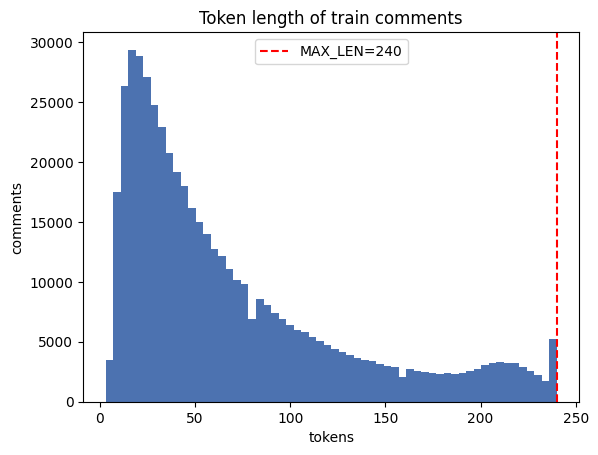

In [8]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(texts, chunk=20_000):
    ids = []
    for i in tqdm(range(0, len(texts), chunk), desc="tokenizing"):
        enc = tok(texts[i:i+chunk], truncation=True, max_length=MAX_LEN, add_special_tokens=True)["input_ids"]
        ids.extend(np.asarray(x, dtype=np.int32) for x in enc)      # int32 arrays: ~4 bytes/token instead of ~36 for Python ints
    return ids

t0 = time.time()
ids_train = encode(train_df[TEXT_COL].tolist())
ids_val   = encode(val_df[TEXT_COL].tolist())
ids_test  = encode(test_df[TEXT_COL].tolist())
print(f"Tokenized in {time.time()-t0:.0f}s")

len_train = np.array([len(x) for x in ids_train])
print(f"Tokens per comment: median {np.median(len_train):.0f}, 95th pct {np.percentile(len_train,95):.0f}, max {len_train.max()}")
print(f"Truncated at {MAX_LEN}: {(len_train >= MAX_LEN).mean():.2%} of train comments")
plt.hist(len_train, bins=60, color="#4c72b0"); plt.axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN={MAX_LEN}")
plt.xlabel("tokens"); plt.ylabel("comments"); plt.title("Token length of train comments"); plt.legend(); plt.show()

## 6. Batching with dynamic padding
Random batches would mix a 5-token comment with a 240-token one and pad everything to 240. Instead:

1. shuffle all comments,
2. cut the shuffled order into big pools (100 batches each),
3. sort inside each pool by length and slice into batches,
4. shuffle the order of the batches.

Each batch then has similar-length comments (little padding, fast) but the order of batches is still random (no training bias). Each epoch uses a different seed, and the order is reproducible, which is what makes resuming from a checkpoint possible.

In [9]:
def make_batches(lengths, bs, shuffle, seed, pool=100):
    lengths = np.asarray(lengths); n = len(lengths); rng = np.random.RandomState(seed)
    if shuffle:
        idx = rng.permutation(n); batches = []
        for s in range(0, n, bs * pool):
            c = idx[s:s + bs * pool]; c = c[np.argsort(lengths[c], kind="stable")]
            batches += [c[i:i + bs] for i in range(0, len(c), bs)]
        rng.shuffle(batches)
        return batches
    order = np.argsort(lengths, kind="stable")                       # inference: sorted by length, restored afterwards
    return [order[i:i + bs] for i in range(0, n, bs)]

def collate(ids_list, idx):
    seqs = [ids_list[i] for i in idx]; L = max(len(s) for s in seqs)
    inp = np.full((len(seqs), L), tok.pad_token_id, dtype=np.int64)
    att = np.zeros((len(seqs), L), dtype=np.int64)
    for j, s in enumerate(seqs):
        inp[j, :len(s)] = s; att[j, :len(s)] = 1
    return {"input_ids": torch.from_numpy(inp).to(device), "attention_mask": torch.from_numpy(att).to(device)}

# quick look at how much padding we save
b = make_batches(len_train, BATCH_SIZE, True, SEED)
padded = sum(len_train[x].max() * len(x) for x in b); real = len_train.sum()
print(f"Bucketed batches: {len(b):,} per epoch | padding overhead {padded/real - 1:.1%} "
      f"(padding everything to {MAX_LEN} would waste {MAX_LEN*len(len_train)/real - 1:.0%})")

Bucketed batches: 7,813 per epoch | padding overhead 1.7% (padding everything to 240 would waste 242%)


## 7. Model, loss and optimiser
`AutoModelForSequenceClassification` puts a small classification head on top of DistilBERT and gives 6 raw scores (logits), one per label. A sigmoid turns each into an independent probability.

**Loss.** `BCEWithLogitsLoss` is the standard loss for multi-label problems. Rare labels (threat 0.24%, sexual_explicit 0.26%) would be ignored without help, so each positive example is up-weighted by `pos_weight`. Member 1's raw weights go up to 424, which makes gradients spiky, so we soften them with a power of 0.5. This is only a training aid: the final precision/recall balance is set later by the per-label thresholds.

**Optimiser.** AdamW with a linear warm-up then linear decay is the usual recipe for fine-tuning transformers. Warm-up avoids wrecking the pre-trained weights in the first few steps. Gradient clipping at 1.0 prevents occasional exploding updates.

In [10]:
id2label = {i: l for i, l in enumerate(LABELS)}; label2id = {l: i for i, l in id2label.items()}
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=N_LABELS, problem_type="multi_label_classification", id2label=id2label, label2id=label2id).to(device)

eff_pos_weight = torch.tensor(POS_WEIGHT ** POS_WEIGHT_POWER, device=device)
print("Effective pos_weight:", dict(zip(LABELS, eff_pos_weight.cpu().numpy().round(2))))
loss_fn = nn.BCEWithLogitsLoss(pos_weight=eff_pos_weight)

no_decay = ["bias", "LayerNorm.weight"]                       # no weight decay on biases and layer norms (standard practice)
groups = [{"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": WEIGHT_DECAY},
          {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],     "weight_decay": 0.0}]
optimizer = torch.optim.AdamW(groups, lr=LR)

steps_per_epoch = len(make_batches(len_train, BATCH_SIZE, True, SEED))
total_steps = steps_per_epoch * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRAC * total_steps), total_steps)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)           # keeps fp16 gradients from underflowing
print(f"{steps_per_epoch:,} steps/epoch x {EPOCHS} epochs = {total_steps:,} steps | params: {sum(p.numel() for p in model.parameters())/1e6:.0f}M")

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Effective pos_weight: {'toxic': np.float32(3.39), 'obscene': np.float32(13.65), 'threat': np.float32(20.58), 'insult': np.float32(4.0), 'identity_hate': np.float32(11.53), 'sexual_explicit': np.float32(19.33)}
7,813 steps/epoch x 2 epochs = 15,626 steps | params: 66M


## 8. Prediction and metric helpers
`predict_probs` runs the model on a list of tokenized comments, sorted by length for speed, and returns an `(n, 6)` array of probabilities in the original order.

Metrics used throughout:
- **F1** at a given threshold (the headline number, per label and macro-averaged),
- **precision / recall** (what the F1 is made of),
- **PR-AUC** (average precision): threshold-free and the honest metric for rare labels,
- **ROC-AUC**: threshold-free, but looks optimistic when positives are rare, so read it next to PR-AUC.

In [11]:
@torch.no_grad()
def predict_probs(ids_list, bs=256, desc="predicting"):
    model.eval()
    lengths = np.array([len(x) for x in ids_list])
    out = np.zeros((len(ids_list), N_LABELS), dtype=np.float32)
    for b in tqdm(make_batches(lengths, bs, False, 0), desc=desc, leave=False):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(**collate(ids_list, b)).logits
        out[b] = torch.sigmoid(logits.float()).cpu().numpy()
    return out

def metrics_table(Y, P, thr, add_macro=True):
    rows = []
    for j, l in enumerate(LABELS):
        yhat = (P[:, j] >= thr[l]).astype(int)
        rows.append({"label": l, "threshold": round(float(thr[l]), 3),
                     "precision": precision_score(Y[:, j], yhat, zero_division=0), "recall": recall_score(Y[:, j], yhat, zero_division=0),
                     "f1": f1_score(Y[:, j], yhat, zero_division=0), "pr_auc": average_precision_score(Y[:, j], P[:, j]),
                     "roc_auc": roc_auc_score(Y[:, j], P[:, j]) if 0 < Y[:, j].sum() < len(Y) else np.nan,
                     "support": int(Y[:, j].sum()), "predicted_positive": int(yhat.sum())})
    df = pd.DataFrame(rows)
    if add_macro:
        m = df[["precision", "recall", "f1", "pr_auc", "roc_auc"]].mean()
        df = pd.concat([df, pd.DataFrame([{"label": "MACRO AVG", **m.to_dict()}])], ignore_index=True)
    return df

THR_DEFAULT = {l: 0.5 for l in LABELS}
rng = np.random.RandomState(SEED)
val_sub_idx = rng.choice(len(val_df), min(VAL_SUBSET_FOR_EPOCH_EVAL, len(val_df)), replace=False)

## 9. Training loop
A hand-written loop (instead of the HF `Trainer`) so every step is visible and explainable.

Each step: tokenised batch to GPU, forward pass under fp16 autocast, weighted BCE loss, backward pass, unscale and clip gradients, optimiser step, scheduler step.

**Safety net for Colab.** A checkpoint (model, optimiser, scheduler, position in the epoch) is written to Drive every `CKPT_EVERY_STEPS` steps. If the session dies, just re-run the notebook from the top: with `RESUME = True` it continues from the last checkpoint, skipping the batches already done. After each epoch the model is scored on a validation subset (macro PR-AUC) and the best epoch is kept in `best_model/`.

In [12]:
CKPT_DIR = OUT_DIR / "checkpoint"; BEST_DIR = OUT_DIR / "best_model"; CKPT_DIR.mkdir(exist_ok=True)
CKPT_FILE = CKPT_DIR / "train_state.pt"
state = {"epoch": 0, "step_in_epoch": 0, "global_step": 0, "history": [], "best_score": -1.0, "log": []}

def save_ckpt():
    torch.save({"model": model.state_dict(), "optim": optimizer.state_dict(), "sched": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "state": state}, CKPT_FILE.with_suffix(".tmp"))
    os.replace(CKPT_FILE.with_suffix(".tmp"), CKPT_FILE)           # atomic: a disconnect mid-write cannot corrupt the old checkpoint

if RESUME and CKPT_FILE.exists() and not DEBUG_SMOKE_TEST:
    ck = torch.load(CKPT_FILE, map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optim"]); scheduler.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"]); state = ck["state"]
    print(f"Resumed from checkpoint: epoch {state['epoch']}, step {state['step_in_epoch']}, global step {state['global_step']}")
else:
    print("Starting fresh.")

t_start = time.time()
for epoch in range(state["epoch"], EPOCHS):
    batches = make_batches(len_train, BATCH_SIZE, True, SEED + epoch)
    start = state["step_in_epoch"] if epoch == state["epoch"] else 0
    model.train(); run_loss, n_run = 0.0, 0
    pbar = tqdm(range(start, len(batches)), initial=start, total=len(batches), desc=f"epoch {epoch+1}/{EPOCHS}")
    for bi in pbar:
        b = batches[bi]
        x = collate(ids_train, b); y = torch.from_numpy(Y_train[b]).to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(**x).logits
        loss = loss_fn(logits.float(), y)                          # loss in fp32 for numerical safety
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer); scaler.update(); scheduler.step()

        run_loss += loss.item(); n_run += 1; state["global_step"] += 1; state["step_in_epoch"] = bi + 1
        if n_run == 100:
            state["log"].append((state["global_step"], run_loss / n_run)); pbar.set_postfix(loss=f"{run_loss/n_run:.4f}"); run_loss, n_run = 0.0, 0
        if state["global_step"] % CKPT_EVERY_STEPS == 0 and not DEBUG_SMOKE_TEST:
            save_ckpt()

    # ---- end of epoch: quick validation ----
    P_sub = predict_probs([ids_val[i] for i in val_sub_idx], desc="val subset")
    m = metrics_table(Y_val[val_sub_idx], P_sub, THR_DEFAULT)
    macro = m[m.label == "MACRO AVG"].iloc[0]
    state["history"].append({"epoch": epoch + 1, "val_macro_f1@0.5": macro.f1, "val_macro_pr_auc": macro.pr_auc, "val_macro_roc_auc": macro.roc_auc})
    print(f"epoch {epoch+1}: macro F1@0.5 = {macro.f1:.4f} | macro PR-AUC = {macro.pr_auc:.4f} | macro ROC-AUC = {macro.roc_auc:.4f}")
    if macro.pr_auc > state["best_score"]:
        state["best_score"] = float(macro.pr_auc); model.save_pretrained(BEST_DIR); tok.save_pretrained(BEST_DIR); print("  new best model saved")
    state["epoch"], state["step_in_epoch"] = epoch + 1, 0
    if not DEBUG_SMOKE_TEST: save_ckpt()

print(f"Training finished in {(time.time()-t_start)/60:.1f} min (this session)")

Starting fresh.


epoch 1/2:   0%|          | 0/7813 [00:00<?, ?it/s]

val subset:   0%|          | 0/118 [00:00<?, ?it/s]

epoch 1: macro F1@0.5 = 0.4921 | macro PR-AUC = 0.5329 | macro ROC-AUC = 0.9776


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

epoch 2/2:   0%|          | 0/7813 [00:00<?, ?it/s]

val subset:   0%|          | 0/118 [00:00<?, ?it/s]

epoch 2: macro F1@0.5 = 0.5067 | macro PR-AUC = 0.5663 | macro ROC-AUC = 0.9804


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  new best model saved
Training finished in 39.2 min (this session)


### 9.1 Training curves
The loss should drop quickly then flatten. A curve that is still falling at the end means more data or epochs would help. Spikes are normal with such rare labels.

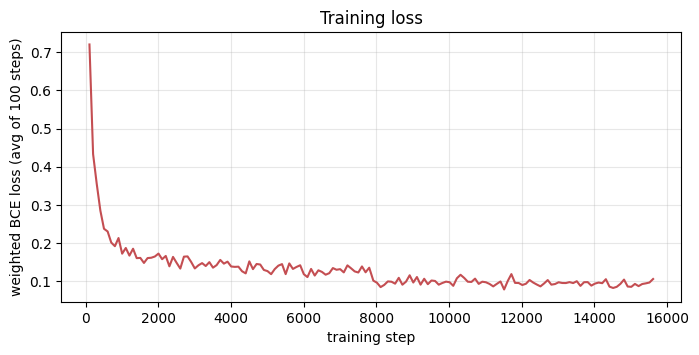

,epoch,val_macro_f1@0.5,val_macro_pr_auc,val_macro_roc_auc
0,1,0.492114,0.532915,0.977634
1,2,0.506736,0.566314,0.980356


In [13]:
if state["log"]:
    s, l = zip(*state["log"])
    plt.figure(figsize=(8, 3.5)); plt.plot(s, l, color="#c44e52")
    plt.xlabel("training step"); plt.ylabel("weighted BCE loss (avg of 100 steps)"); plt.title("Training loss"); plt.grid(alpha=.3)
    plt.savefig(OUT_DIR / "training_loss.png", dpi=150, bbox_inches="tight"); plt.show()
display(pd.DataFrame(state["history"]))

## 10. Reload the best model and tune one threshold per label (on validation)
The model outputs probabilities. Turning them into yes/no needs a threshold, and 0.5 is rarely right: for rare labels the best cut-off is usually lower, for common ones it can differ too.

For each label we scan every possible threshold on the precision-recall curve of the **validation** set and pick the one that maximises F1. These thresholds are saved and used for test evaluation, the Streamlit app and the abstention logic.

Why validation and not test? If we tuned on test, the test score would be optimistic because the thresholds were fitted to it. Test stays untouched until section 11.

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

full validation:   0%|          | 0/691 [00:00<?, ?it/s]

toxic            best threshold 0.720  (val F1 0.695)
obscene          best threshold 0.900  (val F1 0.628)
threat           best threshold 0.863  (val F1 0.456)
insult           best threshold 0.789  (val F1 0.705)
identity_hate    best threshold 0.821  (val F1 0.455)
sexual_explicit  best threshold 0.920  (val F1 0.539)


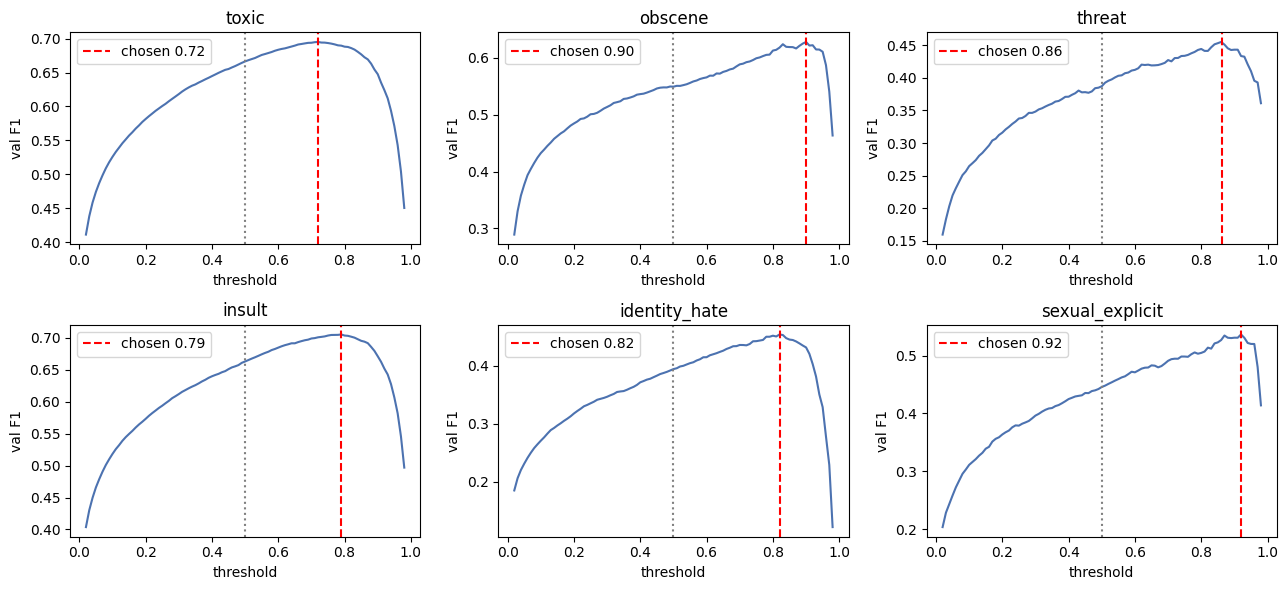

In [14]:
model = AutoModelForSequenceClassification.from_pretrained(BEST_DIR).to(device)
P_val = predict_probs(ids_val, desc="full validation")

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    k = int(np.nanargmax(f1)); return float(thr[k]), float(f1[k])

THRESHOLDS = {}
for j, l in enumerate(LABELS):
    THRESHOLDS[l], f = best_f1_threshold(Y_val[:, j], P_val[:, j])
    print(f"{l:16s} best threshold {THRESHOLDS[l]:.3f}  (val F1 {f:.3f})")

# show the F1-vs-threshold curve so the choice can be defended
fig, axes = plt.subplots(2, 3, figsize=(13, 6)); grid = np.linspace(0.02, 0.98, 97)
for ax, (j, l) in zip(axes.ravel(), enumerate(LABELS)):
    ax.plot(grid, [f1_score(Y_val[:, j], (P_val[:, j] >= t).astype(int), zero_division=0) for t in grid], color="#4c72b0")
    ax.axvline(THRESHOLDS[l], color="red", ls="--", label=f"chosen {THRESHOLDS[l]:.2f}"); ax.axvline(0.5, color="gray", ls=":")
    ax.set_title(l); ax.set_xlabel("threshold"); ax.set_ylabel("val F1"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "threshold_tuning.png", dpi=150, bbox_inches="tight"); plt.show()

## 11. Final evaluation on the test split
Two views of the same predictions: with the default 0.5 threshold and with the tuned thresholds. The tuned table is the headline result. PR-AUC and ROC-AUC do not depend on thresholds, so they are identical in both.

In [15]:
P_test = predict_probs(ids_test, desc="test")
res_default = metrics_table(Y_test, P_test, THR_DEFAULT)
res_tuned   = metrics_table(Y_test, P_test, THRESHOLDS)
print("TEST, default threshold 0.5"); display(res_default.round(4))
print("TEST, tuned thresholds (headline result)"); display(res_tuned.round(4))

# micro F1 (pools all label decisions, dominated by the common label) and exact-match accuracy, for completeness
Yhat = np.column_stack([(P_test[:, j] >= THRESHOLDS[l]).astype(int) for j, l in enumerate(LABELS)])
print(f"micro F1 = {f1_score(Y_test, Yhat, average='micro'):.4f} | exact-match (all 6 labels right) = {(Yhat == Y_test).all(axis=1).mean():.4f}")
res_tuned.to_csv(OUT_DIR / "metrics_test.csv", index=False); res_default.to_csv(OUT_DIR / "metrics_test_threshold0.5.csv", index=False)

test:   0%|          | 0/691 [00:00<?, ?it/s]

TEST, default threshold 0.5


,label,threshold,precision,recall,f1,pr_auc,roc_auc,support,predicted_positive
0,toxic,0.5,0.5661,0.8153,0.6682,0.7803,0.9655,14131.0,20351.0
1,obscene,0.5,0.4137,0.8204,0.5501,0.6369,0.9878,941.0,1866.0
2,threat,0.5,0.2569,0.5971,0.3592,0.4131,0.9850,407.0,946.0
3,insult,0.5,0.5513,0.8435,0.6668,0.7901,0.9755,10452.0,15990.0
4,identity_hate,0.5,0.2705,0.7420,0.3964,0.4412,0.9835,1318.0,3616.0
5,sexual_explicit,0.5,0.3072,0.7286,0.4322,0.5300,0.9846,420.0,996.0
6,MACRO AVG,NaN,0.3943,0.7578,0.5122,0.5986,0.9803,NaN,NaN


TEST, tuned thresholds (headline result)


,label,threshold,precision,recall,f1,pr_auc,roc_auc,support,predicted_positive
0,toxic,0.720,0.6806,0.7137,0.6968,0.7803,0.9655,14131.0,14819.0
1,obscene,0.900,0.5825,0.6376,0.6088,0.6369,0.9878,941.0,1030.0
2,threat,0.863,0.4057,0.4545,0.4287,0.4131,0.9850,407.0,456.0
3,insult,0.789,0.7082,0.6977,0.7029,0.7901,0.9755,10452.0,10297.0
4,identity_hate,0.821,0.3998,0.5175,0.4511,0.4412,0.9835,1318.0,1706.0
5,sexual_explicit,0.920,0.5403,0.5429,0.5416,0.5300,0.9846,420.0,422.0
6,MACRO AVG,NaN,0.5528,0.5940,0.5716,0.5986,0.9803,NaN,NaN


micro F1 = 0.6764 | exact-match (all 6 labels right) = 0.9340


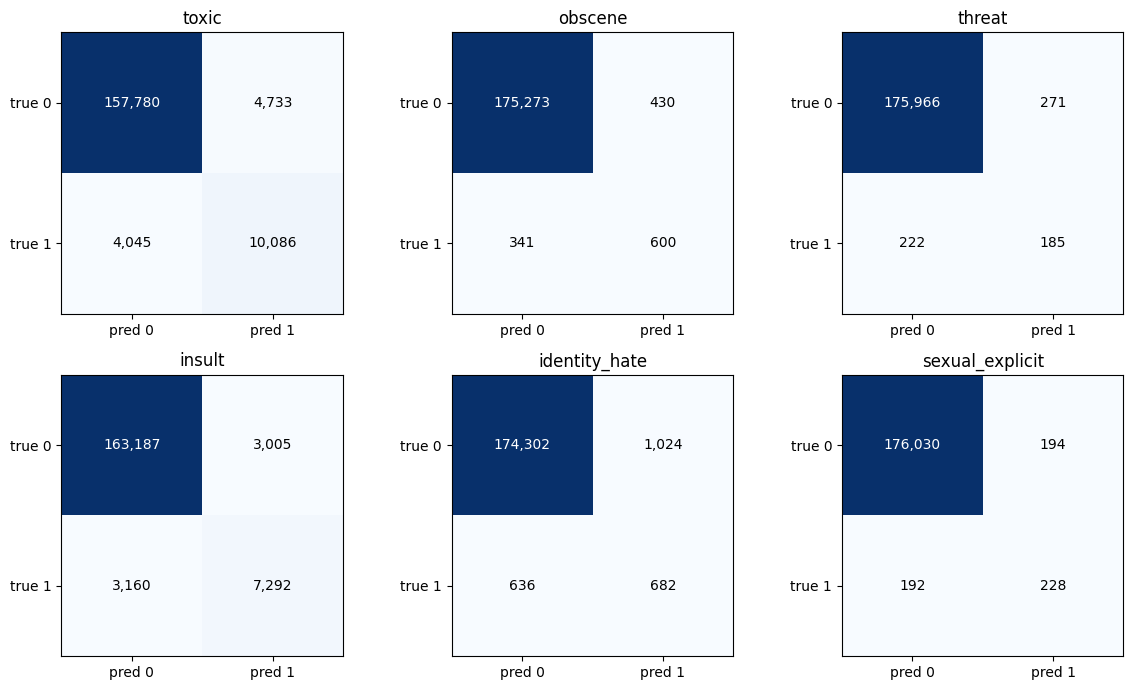

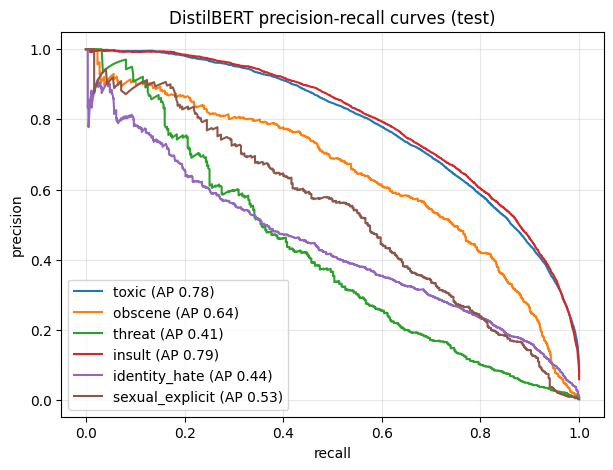

In [16]:
# Confusion matrices (one 2x2 per label) at the tuned thresholds
cms = multilabel_confusion_matrix(Y_test, Yhat)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, l, cm in zip(axes.ravel(), LABELS, cms):
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true 0", "true 1"]); ax.set_title(l)
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrices_test.png", dpi=150, bbox_inches="tight"); plt.show()

# Precision-recall curves
plt.figure(figsize=(7, 5))
for j, l in enumerate(LABELS):
    p, r, _ = precision_recall_curve(Y_test[:, j], P_test[:, j]); plt.plot(r, p, label=f"{l} (AP {average_precision_score(Y_test[:, j], P_test[:, j]):.2f})")
plt.xlabel("recall"); plt.ylabel("precision"); plt.title("DistilBERT precision-recall curves (test)"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(OUT_DIR / "pr_curves_test.png", dpi=150, bbox_inches="tight"); plt.show()

## 12. Compare with Member 1's TF-IDF + Logistic Regression baseline
For a fair comparison both models must be scored on the **same test split with the same metrics**. Fill in the baseline numbers in one of two ways:

- **Best:** ask Member 1 for a CSV with columns `label, precision, recall, f1, pr_auc, roc_auc` (one row per label, evaluated on `test.parquet`) and set `BASELINE_CSV` to its path.
- **Quick:** type the baseline per-label F1 into `BASELINE_F1` below.

Ask Member 1 whether their baseline thresholds were tuned. If the baseline used 0.5 and ours uses tuned thresholds, compare against the same-threshold version, or tune both on val, otherwise the comparison is not fair.

In [17]:
BASELINE_CSV = ""        # e.g. "/content/drive/MyDrive/toxic_project/baseline_metrics_test.csv"
BASELINE_F1  = {l: None for l in LABELS}     # e.g. {"toxic": 0.62, "obscene": 0.55, ...} if you only have F1

if BASELINE_CSV and Path(BASELINE_CSV).exists():
    base = pd.read_csv(BASELINE_CSV).set_index("label")
elif all(v is not None for v in BASELINE_F1.values()):
    base = pd.DataFrame({"f1": BASELINE_F1})
else:
    base = None

if base is None:
    print("Baseline numbers not provided yet. Fill BASELINE_CSV or BASELINE_F1 and re-run this cell.")
else:
    d = res_tuned[res_tuned.label.isin(LABELS)].set_index("label")
    cmp = pd.DataFrame({"baseline_f1": base["f1"].reindex(LABELS), "distilbert_f1": d["f1"]})
    for extra in ["pr_auc", "precision", "recall"]:
        if extra in base.columns: cmp[f"baseline_{extra}"] = base[extra].reindex(LABELS); cmp[f"distilbert_{extra}"] = d[extra]
    cmp["f1_gain"] = cmp["distilbert_f1"] - cmp["baseline_f1"]
    cmp.loc["MACRO AVG"] = cmp.mean(numeric_only=True)
    display(cmp.round(4)); cmp.to_csv(OUT_DIR / "baseline_vs_distilbert.csv")
    ax = cmp.loc[LABELS, ["baseline_f1", "distilbert_f1"]].plot.bar(figsize=(9, 4), color=["#8c8c8c", "#4c72b0"], rot=20)
    ax.set_ylabel("test F1"); ax.set_title("TF-IDF + LR baseline vs DistilBERT"); plt.tight_layout()
    plt.savefig(OUT_DIR / "baseline_vs_distilbert.png", dpi=150, bbox_inches="tight"); plt.show()

Baseline numbers not provided yet. Fill BASELINE_CSV or BASELINE_F1 and re-run this cell.


## 13. Error analysis
Numbers say how often the model is wrong, reading the mistakes says why. Below are the most confident false positives (model sure it is toxic, annotators said no) and false negatives (toxic comments the model missed). These are good examples for the report, and the false positives that mention identity terms are a useful lead for Member 3.

In [18]:
def show_errors(label, kind, k=8):
    j = LABELS.index(label); y = Y_test[:, j]; p = P_test[:, j]
    mask = (y == 0) if kind == "false_positive" else (y == 1)
    idx = np.where(mask)[0]; idx = idx[np.argsort(-p[idx] if kind == "false_positive" else p[idx])][:k]
    print(f"\n=== {label}: top {k} {kind.replace('_', ' ')}s ===")
    for i in idx: print(f"[p={p[i]:.2f}] " + textwrap.shorten(test_df[TEXT_COL].iloc[i], 230))

show_errors("toxic", "false_positive"); show_errors("toxic", "false_negative")
show_errors("identity_hate", "false_positive", 5)


=== toxic: top 8 false positives ===
[p=1.00] Spoken like a true idiotic mainland haole.
[p=1.00] The word "stupid" is redundant.
[p=1.00] I did a little time in my young and stupid years. Trust me, he will be a marked man in prison. Pedi's and woman beaters are the bottom rung in the joint.
[p=1.00] Was about to make a trivial stupid comment by decided not to. More people should try this.
[p=1.00] BUBBA---YOUR CAP KEY IS STUCK
[p=1.00] This will continue as long as the most base and stupid portion of our population wants it. I call it the "misery loves company" policy, where those finger-pointing losers who "feel" life has been unfair to them - it can't be [...]
[p=1.00] Maybe on the 446th time, fact-free moron Trump sheep like you will read it.
[p=1.00] Lol,it's not hard to make me look stupid . I probably should not have opted for the G.E.D and went to college instead of mowing lawns ,smoking pot and playing guitar , whatever Go Broncos

=== toxic: top 8 false negatives ===
[p=0.00

## 14. Save everything for the team
Saved to `OUT_DIR` on Drive:

- `final_model/` and `tokenizer/`: load with `from_pretrained` (see section 15),
- `thresholds.json`: one decision threshold per label,
- `val_predictions.parquet` and `test_predictions.parquet`: probabilities next to labels, text, `id` and the identity columns. **Member 3** uses the test file for subgroup false-positive/false-negative rates. **Member 4** uses the val file to fit calibration and the abstention band, and the test file to measure the result,
- `model_config.json`: everything needed to reproduce the run.

In [19]:
final_dir = OUT_DIR / "final_model"; tok_dir = OUT_DIR / "tokenizer"
model.save_pretrained(final_dir); tok.save_pretrained(tok_dir)
json.dump(THRESHOLDS, open(OUT_DIR / "thresholds.json", "w"), indent=2)

def pred_frame(df, P, Y):
    out = df.drop(columns=[c for c in LABELS if c in df.columns]).copy()
    for j, l in enumerate(LABELS): out[f"true_{l}"] = Y[:, j]
    for j, l in enumerate(LABELS): out[f"prob_{l}"] = P[:, j]
    return out
pred_frame(val_df, P_val, Y_val).to_parquet(OUT_DIR / "val_predictions.parquet", index=False)
pred_frame(test_df, P_test, Y_test).to_parquet(OUT_DIR / "test_predictions.parquet", index=False)

mc = res_tuned.set_index("label")
json.dump({"model_name": MODEL_NAME, "labels": LABELS, "max_len": MAX_LEN, "text_column": TEXT_COL,
           "train_rows_used": len(train_df), "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "warmup_frac": WARMUP_FRAC,
           "weight_decay": WEIGHT_DECAY, "pos_weight_power": POS_WEIGHT_POWER, "seed": SEED, "thresholds": THRESHOLDS,
           "test_macro_f1_tuned": float(mc.loc["MACRO AVG", "f1"]), "test_macro_pr_auc": float(mc.loc["MACRO AVG", "pr_auc"]),
           "input_preprocessing": "toxic_preprocessing.clean_text (NOT lowercased)",
           "training_history": state["history"]}, open(OUT_DIR / "model_config.json", "w"), indent=2)
print("Saved to", OUT_DIR); print(sorted(p.name for p in OUT_DIR.iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to /content/drive/MyDrive/toxic_project/member2_outputs
['best_model', 'checkpoint', 'confusion_matrices_test.png', 'final_model', 'metrics_test.csv', 'metrics_test_threshold0.5.csv', 'model_config.json', 'pr_curves_test.png', 'test_predictions.parquet', 'threshold_tuning.png', 'thresholds.json', 'tokenizer', 'training_loss.png', 'val_predictions.parquet']


## 15. How the others load and use the model
This is also a final end-to-end check that the saved files work. Members 4 and 5 should follow the same pattern: **clean with `toxic_preprocessing.clean_text` first** (the model was trained on cleaned text, and skipping this lowers accuracy), then tokenize, run the model, apply `thresholds.json`.

If `toxic_preprocessing.py` is not in the Colab working folder, upload it first (it is in Member 1's deliverables).

In [20]:
try:
    from toxic_preprocessing import clean_text
except ImportError:
    print("toxic_preprocessing.py not found next to the notebook: using raw text for this demo only.")
    clean_text = lambda s: s

tok_loaded = AutoTokenizer.from_pretrained(tok_dir)
mdl_loaded = AutoModelForSequenceClassification.from_pretrained(final_dir).to(device).eval()
thr_loaded = json.load(open(OUT_DIR / "thresholds.json"))

@torch.no_grad()
def predict_comments(texts):
    enc = tok_loaded([clean_text(t) for t in texts], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
    probs = torch.sigmoid(mdl_loaded(**enc).logits).cpu().numpy()
    return pd.DataFrame([{**{f"p_{l}": round(float(p[j]), 3) for j, l in enumerate(LABELS)},
                          "flags": [l for j, l in enumerate(LABELS) if p[j] >= thr_loaded[l]]} for p in probs], index=texts)

display(predict_comments([
    "Thank you for writing this, I learned a lot.",
    "You are a complete idiot and nobody wants you here.",
    "I am a gay woman and I loved this article.",
    "I will find you and make you regret this.",
]))
# sanity check: reloaded model must reproduce the stored test probabilities
model = mdl_loaded   # predict_probs uses the global `model`: point it at the reloaded copy
chk = predict_probs(ids_test[:512]); print("max abs diff vs stored probs (should be ~0):", float(np.abs(chk - P_test[:512]).max()))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,p_toxic,p_obscene,p_threat,p_insult,p_identity_hate,p_sexual_explicit,flags
"Thank you for writing this, I learned a lot.",0.000,0.000,0.000,0.000,0.000,0.000,[]
You are a complete idiot and nobody wants you here.,0.999,0.019,0.011,0.999,0.010,0.005,"[toxic, insult]"
I am a gay woman and I loved this article.,0.658,0.002,0.002,0.048,0.884,0.003,[identity_hate]
I will find you and make you regret this.,0.016,0.000,0.012,0.002,0.000,0.000,[]


predicting:   0%|          | 0/2 [00:00<?, ?it/s]

max abs diff vs stored probs (should be ~0): 0.00019037723541259766
